PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [152]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [153]:
elo_df= pd.read_csv("understat_team_elo_with_seasonal_elo.csv")

In [154]:
elo_df.columns

Index(['id', 'fid', 'h', 'a', 'league_id', 'season', 'h_goals', 'a_goals',
       'team_h', 'team_a', 'league', 'h_xg', 'a_xg', 'h_d', 'h_deep', 'a_deep',
       'a_ppda', 'h_ppda', 'Shots on target per total shots_home',
       'Shots on target per total shots_away', 'date_for_clubelo',
       'Elo_team_h', 'date', 'Elo_team_a', 'Season', 'Seasonal_Elo_Home',
       'Seasonal_Elo_Away'],
      dtype='object')

In [155]:
elo_df

,id,fid,h,a,league_id,season,h_goals,a_goals,team_h,team_a,...,h_ppda,Shots on target per total shots_home,Shots on target per total shots_away,date_for_clubelo,Elo_team_h,date,Elo_team_a,Season,Seasonal_Elo_Home,Seasonal_Elo_Away
0,81,958431,89,82,1,2015,1,0,Manchester United,Tottenham,...,13.8261,0.111111,0.444444,2015-08-08,1810.338257,2015-08-08,1730.680176,2015.0,1548.445255,1490.977949
1,82,958427,73,71,1,2015,0,1,Bournemouth,Aston Villa,...,6.9000,0.181818,0.428571,2015-08-08,1594.601929,2015-08-08,1577.901123,2015.0,1529.966365,1508.626453
2,83,958429,72,90,1,2015,2,2,Everton,Watford,...,6.6500,0.500000,0.454545,2015-08-08,1706.561157,2015-08-08,1574.087280,2015.0,1539.314839,1500.000000
3,84,958430,75,77,1,2015,4,2,Leicester,Sunderland,...,10.8800,0.421053,0.454545,2015-08-08,1633.624390,2015-08-08,1605.132446,2015.0,1551.429377,1488.337848
4,85,958433,79,78,1,2015,1,3,Norwich,Crystal Palace,...,5.7368,0.352941,0.636364,2015-08-08,1615.207520,2015-08-08,1646.781494,2015.0,1528.013844,1511.048542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22270,1729426,78,71,1,2023,5,0,Crystal Palace,Aston Villa,...,14.4783,0.600000,0.250000,2024-05-19,1742.572754,2024-05-19,1787.570190,2023.0,1551.635503,1518.700489
3416,22271,1729428,87,229,1,2023,2,0,Liverpool,Wolverhampton Wanderers,...,5.0968,0.388889,0.750000,2024-05-19,1897.344116,2024-05-19,1681.206665,2023.0,1606.106889,1483.333786
3417,22272,1729431,256,228,1,2023,2,4,Luton,Fulham,...,13.8947,0.400000,0.466667,2024-05-19,1572.353638,2024-05-19,1707.895386,2023.0,1476.604344,1484.624228
3418,22273,1729434,88,81,1,2023,3,1,Manchester City,West Ham,...,8.0000,0.428571,0.666667,2024-05-19,2048.742920,2024-05-19,1728.072998,2023.0,1635.086569,1477.754934


In [156]:
cleaned_df = elo_df.drop(columns=["fid", "h", "a", "league_id", "league", "season", "team_h", "team_a", "date_for_clubelo", "date", "Season", "h_d"])

In [157]:
max_clubelo_h= cleaned_df["Elo_team_h"].max()
min_clubelo_h= cleaned_df["Elo_team_h"].min()
max_clubelo_a= cleaned_df["Elo_team_a"].max()
min_clubelo_a= cleaned_df["Elo_team_a"].min()


In [158]:
max_clubelo_h, min_clubelo_h, max_clubelo_a, min_clubelo_a

(2088.26196289, 1499.45239258, 2090.13623047, 1475.79931641)

In [159]:
clubelo_difference = max_clubelo_a - min_clubelo_a
clubelo_difference

614.33691406

In [160]:
max_seasonal_elo_h = cleaned_df["Seasonal_Elo_Home"].max()
min_seasonal_elo_h = cleaned_df["Seasonal_Elo_Home"].min()
max_seasonal_elo_a = cleaned_df["Seasonal_Elo_Away"].max()
min_seasonal_elo_a = cleaned_df["Seasonal_Elo_Away"].min()
max_seasonal_elo_h, min_seasonal_elo_h, max_seasonal_elo_a, min_seasonal_elo_a

(1655.1306916195538, 1413.6051204812252, 1611.497297472608, 1380.1200149275874)

In [161]:
seasonal_elo_difference = max_seasonal_elo_h - min_seasonal_elo_h
seasonal_elo_difference

241.5255711383286

In [162]:
adjusted_EA_division= seasonal_elo_difference * 400 / clubelo_difference
adjusted_EA_division

157.25935760047113

In [163]:
# Assign the difference from home to away for all home/away columns
cleaned_df["Seasonal Elo Difference"] = cleaned_df["Seasonal_Elo_Home"] - cleaned_df["Seasonal_Elo_Away"]
cleaned_df["ClubElo Difference"] = cleaned_df["Elo_team_h"] - cleaned_df["Elo_team_a"]
cleaned_df["Goal Difference"] = cleaned_df["h_goals"] - cleaned_df["a_goals"]
cleaned_df["xG Difference"] = cleaned_df["h_xg"] - cleaned_df["a_xg"]
cleaned_df["DEEP Difference"] = cleaned_df["h_deep"] - cleaned_df["a_deep"]
cleaned_df["PPDA Difference"] = cleaned_df["h_ppda"] - cleaned_df["a_ppda"]
cleaned_df["Shots on target per total shots Difference"] = cleaned_df["Shots on target per total shots_home"] - cleaned_df["Shots on target per total shots_away"]

cleaned_df["Expected Chance of Success ClubElo"] = 1/(1+ 10**((cleaned_df["ClubElo Difference"])/400))
cleaned_df["Expected Chance of Success Seasonal Elo"] = 1/(1+ 10**((cleaned_df["Seasonal Elo Difference"])/157.2594))


In [164]:
# Dropping the original home/away columns
cleaned_df = cleaned_df.drop(columns=["Seasonal_Elo_Home", "Seasonal_Elo_Away", 
                                      "Elo_team_h", "Elo_team_a", "h_goals", 
                                      "a_goals", "h_xg", "a_xg", "h_deep", "a_deep", 
                                      "h_ppda", "a_ppda", "Shots on target per total shots_home", 
                                      "Shots on target per total shots_away","Seasonal Elo Difference", "ClubElo Difference"]) # 

In [165]:
cleaned_df

,id,Goal Difference,xG Difference,DEEP Difference,PPDA Difference,Shots on target per total shots Difference,Expected Chance of Success ClubElo,Expected Chance of Success Seasonal Elo
0,81,1,-0.047061,-6,5.6073,-0.333333,0.387330,0.301233
1,82,-1,0.093853,9,-4.9462,-0.246753,0.475984,0.422515
2,83,0,0.046334,1,-10.5079,0.045455,0.318086,0.359935
3,84,2,1.108570,-1,1.3244,-0.033493,0.459088,0.284188
4,85,-2,-0.978990,-5,-4.8882,-0.283422,0.545314,0.438216
...,...,...,...,...,...,...,...,...
3415,22270,5,1.633044,11,-15.8217,0.350000,0.564397,0.381725
3416,22271,2,4.928116,21,-11.5032,-0.361111,0.223708,0.142139
3417,22272,-2,0.951450,-1,3.3947,-0.066667,0.685732,0.529323
3418,22273,2,2.074881,16,-55.0000,-0.238095,0.136352,0.090822


In [168]:
def plot_correlation_matrix(df, threshold=0.70):
    """
    Plots a heatmap showing only strong positive or negative correlations (|r| >= threshold).

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - threshold (float): Absolute correlation threshold to display (default: 0.75).
    """
    corr = df.corr()

    # Keep only strong correlations, zero-out weak ones (keeps signs intact)
    filtered_corr = corr.where(corr.abs() >= threshold)

    plt.figure(figsize=(18, 13))
    sns.heatmap(filtered_corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True,
                mask=filtered_corr.isnull(), square=True, linewidths=0.5, linecolor='gray')
    plt.title(f'Correlation Heatmap (|r| ≥ {threshold})')
    plt.tight_layout()
    plt.show()

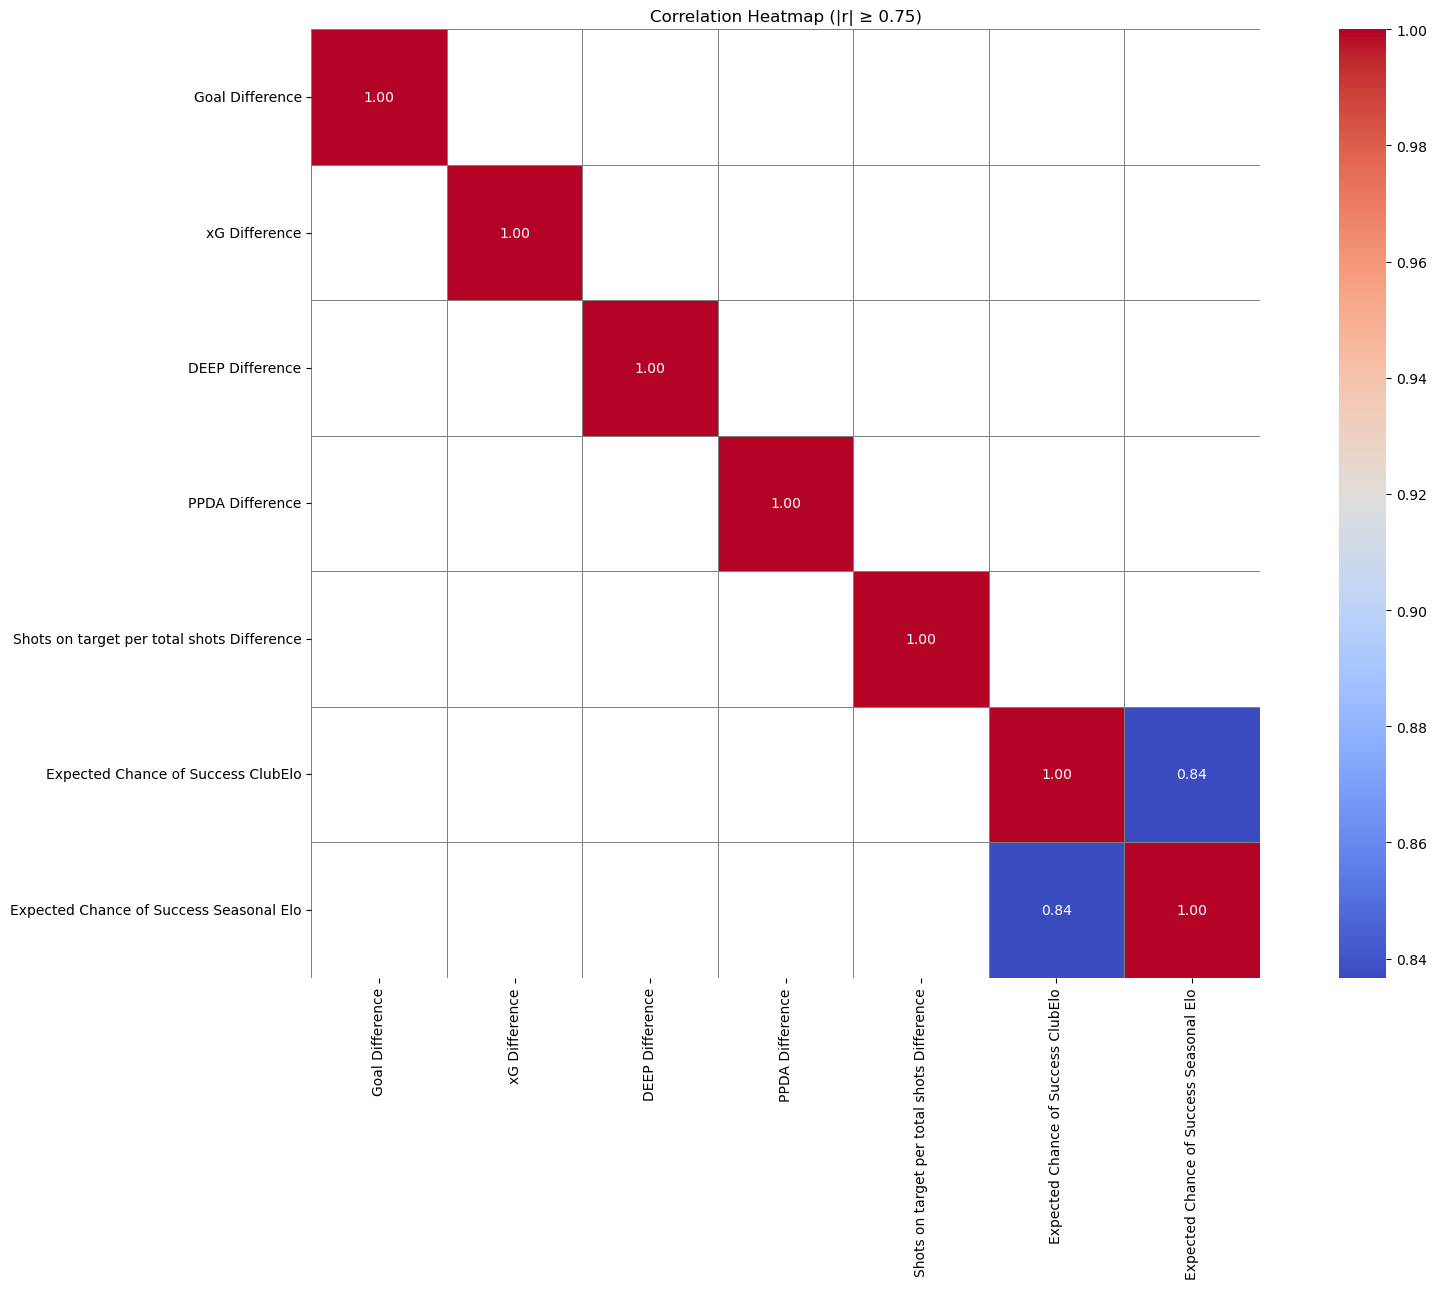

In [167]:
plot_correlation_matrix(cleaned_df.drop(columns=["id" ]))

In [169]:
elo_df.to_csv("elo_cleaned.csv", index=False)